# Main notebook for Optics to MRI registration

In [1]:
# Import libraries and functions
from module.utils import *
from module.utils_BRATS import *
from module.main_functions import *


id_patient = 0

# Indicate the path where MR volumes and optical images are located
Patient_ID_array = np.array(["P_077"])
print("Patient",Patient_ID_array[id_patient])


Mypath = Paths("/home/caredda/Videos/Optical_MRI_data/" + Patient_ID_array[id_patient], RGB_optics=True)


# #####################
# # Path and filenames
# #####################
# main_path = "/home/caredda/Videos/Optical_MRI_data/" + Patient_ID_array[id_patient]

# # main_path_optics = main_path + "/optics_HSI/"  #HSI
# main_path_optics = main_path + "/optics/" # RGB



# Load parameters
params = Params()



params_file = Mypath.main_path+"/Params.json"
if os.path.exists(params_file):
    print("Param file exists")
    params = Params.load(params_file)
else:
    print("Param file does not exist")



Patient P_077
Param file exists


# [Debug] Check MRI resolution

In [3]:
# Import libraries and functions
from module.utils import *
from module.utils_BRATS import *
from module.main_functions import *


id_patient = 5

# Get all folder in the main path
dirs = glob.glob("/home/caredda/Videos/Optical_MRI_data/*")

for dir in dirs:
    Mypath = Paths(dir, RGB_optics=True)

    if os.path.exists(Mypath.output_dir + "/r_T1_bet.nii.gz"): 
        itk_img = itk.imread(Mypath.output_dir + "/r_T1_bet.nii.gz")
        print(dir, itk_img.GetSpacing())
    
    





# # Indicate the path where MR volumes and optical images are located
# Patient_ID_array = np.array(["P_025", "P_027", "P_028", "P_031", "P_033", "P_035", "P_040", "P_054", "P_055", "P_058", "P_059", "P_060", "P_064", "P_066", "P_068"])
# print("Patient",Patient_ID_array[id_patient])


# Mypath = Paths("/home/caredda/Videos/Optical_MRI_data/" + Patient_ID_array[id_patient], RGB_optics=True)


# # Load parameters
# params = Params()


/home/caredda/Videos/Optical_MRI_data/P_035 itkVectorD3 ([0.46875, 0.46875, 0.8])
/home/caredda/Videos/Optical_MRI_data/P_032 itkVectorD3 ([0.46875, 0.46875, 0.8])
/home/caredda/Videos/Optical_MRI_data/P_075 itkVectorD3 ([0.697674, 0.346741, 0.346741])
/home/caredda/Videos/Optical_MRI_data/P_059 itkVectorD3 ([0.46875, 0.46875, 0.8])
/home/caredda/Videos/Optical_MRI_data/P_061 itkVectorD3 ([0.46875, 0.46875, 0.8])
/home/caredda/Videos/Optical_MRI_data/P_023 itkVectorD3 ([1.17188, 1.17188, 1.5])
/home/caredda/Videos/Optical_MRI_data/P_033 itkVectorD3 ([0.46875, 0.46875, 0.8])
/home/caredda/Videos/Optical_MRI_data/P_045 itkVectorD3 ([1, 1, 1])
/home/caredda/Videos/Optical_MRI_data/P_081 itkVectorD3 ([0.44405, 0.44405, 0.42654])
/home/caredda/Videos/Optical_MRI_data/P_060 itkVectorD3 ([0.46875, 0.46875, 0.8])
/home/caredda/Videos/Optical_MRI_data/P_066 itkVectorD3 ([1.17188, 1.17188, 1.5])
/home/caredda/Videos/Optical_MRI_data/P_083 itkVectorD3 ([0.497512, 0.497512, 0.531165])
/home/caredd

# Extract brain surface

TODO: split brain extraction and surface extraction

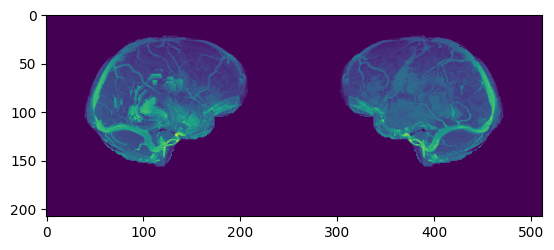

In [ ]:
error = main_extract_brain(Mypath, params)
print(error)

error = main_get_surface_mask(Mypath, params)
print(error)

error, proj = main_plot_extracted_brain(Mypath)

plt.figure()
plt.imshow(proj)


# Get tumor segmentation in T1 space

In [2]:
error = main_get_tumor_segmentation(Mypath)
print(error)



  Writing image ...

  Writing image ...


2025-04-10 15:31:28.233 | INFO     | brats.core.brats_algorithm:__init__:46 - Instantiated AdultGliomaSegmenter with algorithm: BraTS23_1 by André Ferreira, et al.
2025-04-10 15:31:28.236 | INFO     | brats.utils.data_handling:add_log_file_handler:41 - Logging console logs and further debug information to: /home/caredda/Videos/Optical_MRI_data/P_031/results/log.txt
2025-04-10 15:31:28.236 | INFO     | brats.core.brats_algorithm:_infer_single:121 - Performing single inference
2025-04-10 15:31:28.247 | INFO     | brats.core.docker:_log_algorithm_info:276 - Running algorithm: BraTS23 Adult Glioma Segmentation [1st place]
2025-04-10 15:31:28.248 | INFO     | brats.core.docker:_log_algorithm_info:279 - (Paper) Consider citing the corresponding paper: https://arxiv.org/abs/2402.17317v1 by André Ferreira, et al.
2025-04-10 15:31:29.744 | INFO     | brats.core.docker:run_container:329 - Starting inference


Output()

2025-04-10 15:34:45.649 | INFO     | brats.core.docker:run_container:349 - Finished inference in 195.90 seconds
2025-04-10 15:34:45.650 | INFO     | brats.core.brats_algorithm:_infer_single:144 - Saved output to: /home/caredda/Videos/Optical_MRI_data/P_031/results/segmentation_atlas_space.nii.gz


Success


# [Debug] Test preprocess BRATS segmentation

In [ ]:
main_path = Mypath.main_path
output_dir = Mypath.output_dir


main_path_MRI = main_path + "/MRI/"

filename_t1 = main_path_MRI+"T1.nii"
filename_flair = main_path_MRI+"FLAIR.nii"
filename_t1_bet = output_dir+"r_T1_bet.nii.gz"


#Preprocess data in BRATS space
param_transform_atlas = preprocess_exam_in_brats_style_ITK(filename_t1, filename_flair, filename_t1_bet, output_dir)




#Free GPU cache
torch.cuda.empty_cache()


#Process tumor segmentation
segmenter = AdultGliomaSegmenter()
segmenter.infer_single(
    t1c = output_dir+"r_T1_bet_atlas.nii.gz",
    t1n = output_dir+"r_T1_bet_atlas.nii.gz",
    t2f = output_dir+"r_FLAIR_bet_atlas.nii.gz",
    t2w = output_dir+"r_FLAIR_bet_atlas.nii.gz",
    output_file=output_dir+"segmentation_atlas_space.nii.gz",
    log_file = output_dir+"log.txt"
)


# Registration back to T1 space")
filename_tumor = output_dir+ "segmentation_atlas_space.nii.gz"

register_tumor_segmentation_to_T1_space(output_dir, filename_t1_bet, filename_tumor, param_transform_atlas)

# Register fMRI on T1

A rigid transform is used because fMRI are usually cropped. If an affine transform is used, the registered volume does not fit the brain.

Success
256 256
Success


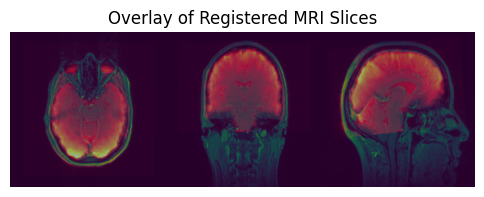

In [2]:

# params.register_fMRI_to_T1 = True
error = main_register_fMRI_to_T1(Mypath, params)
print(error)


error, slice_T1, slice_fMRI = main_plot_fMRI_T1_registration(Mypath)
print(error)


# Plot overlay of registered slices
plt.figure(figsize=(6,6))
plt.imshow(slice_T1)  # Base image
plt.imshow(slice_fMRI, cmap="hot", alpha=0.5)  # Overlay with transparency
plt.axis("off")
plt.title("Overlay of Registered MRI Slices")
plt.show()





# Rotation of the MRI volume and projection with an angle

1) Load the MRI volumes
2) Calculate the center of gravitiy of the tumor segmenation
3) Calculate a new orthonormal basis. Consider that the vector between the center of mass of the tumor and the origin of MRI is the z axis
4) Calculate rotation matrix between origin basis and the new orthonormal basis
5) Create an affine transform
6) Use the resampling filter to apply the transform
7) Process the projections

Spacing projection [0.46875, 0.46875]
Success
Success


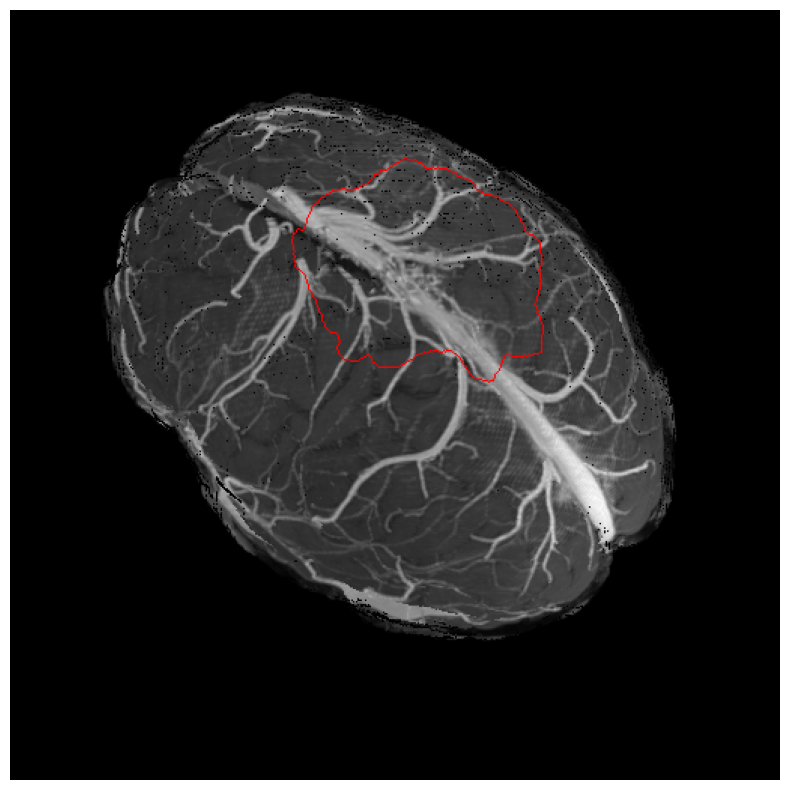

In [4]:
#Get MRI projection
# params.projection_type = "Transverse"
# params.projection_type = "Sagital"
# params.projection_type = "Coronal"
error = main_get_MRI_projection(Mypath, params)
print(error)


#Plot projection
error, proj = main_plot_MRI_Projection(Mypath)
print(error)

plt.figure(figsize=(10,10))
plt.imshow(proj)
plt.axis('off')
plt.show()


# [Debug] Test projection v2

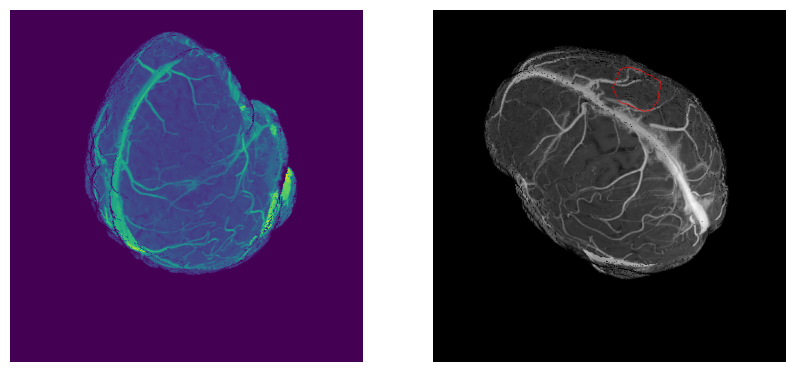

In [16]:

output_dir = Mypath.output_dir
#################
# Load mri volume
#################



filename_t1 = output_dir + "r_T1_bet.nii.gz"
filename_surface_mask = output_dir+'surface_mask.nii.gz'
filename_tumor = output_dir+'r_tumor_mask.nii.gz'



# Load anatomical MRI
T1 = itk.imread(filename_t1, itk.F)
surface = itk.imread(filename_surface_mask, itk.F)
tumor = itk.imread(filename_tumor, itk.F)

##################################
# Calculate the rotation transform
##################################

# Get center of mass of the tumor
center_of_mass_tumor_itk = getGravityCenter(tumor)
center_of_mass_MRI = getGravityCenter(surface)


# Calculate a new orthonormal basis. Consider that the vector between the center of mass of the tumor and the origin of MRI is the z axis
# Vector between the center of mass of the tumor and the point at the surface
vector_Tumor_surface = vector(center_of_mass_tumor_itk,surface.GetOrigin())



# Get the orthogonal matrix such as the vector is the new z-axis of the base
# new_directionMatrix, new_directionMatrix_itk  = orthonormal_basis_from_Y_vector(vector_Tumor_surface)
# new_directionMatrix, new_directionMatrix_itk  = orthonormal_basis_from_X_vector(vector_Tumor_surface)
new_directionMatrix, new_directionMatrix_itk  = orthonormal_basis_from_Z_vector(vector_Tumor_surface)



# Calculate rotation matrix between origin direction and new new_directionMatrix
mri_base = itk.array_from_matrix(T1.GetDirection())
R = np.dot(new_directionMatrix, np.linalg.inv(mri_base))

#Calculate translation vector
T = np.zeros((3,))


#######################
# Apply Rotation
#######################
center = center_of_mass_MRI
# center = center_of_mass_tumor_itk
surface = Apply_Afffine_Transform(R, T, surface, center, "")
T1 = Apply_Afffine_Transform(R, T, T1, center, "")
tumor = Apply_Afffine_Transform(R, T, tumor, center, "")



#######################
# Calculate projection T1
#######################
# Get numpy arrays
np_T1 = itk.GetArrayFromImage(T1)
np_surface = itk.GetArrayFromImage(surface)
np_tumor = itk.GetArrayFromImage(tumor)


# Calculate projection
np_MRI_projection, np_mask, np_tumor_mask = create_MRI_projection_np(np_T1,
                                                                    np_surface,
                                                                    np_tumor,
                                                                    Projection=params.projection_type)



# if center_of_mass_tumor[id_axis]>center_of_mass_brain[id_axis]:
#     id_proj = -1
# else:
#     id_proj = 0

#Plot projection
plt.figure(figsize=(10,10))
plt.subplot(121)
plt.imshow(np_MRI_projection)
plt.axis('off')


#Plot projection
error, proj = main_plot_MRI_Projection(Mypath)

plt.subplot(122)
plt.imshow(proj)
plt.axis('off')
plt.show()

# Contrast enhancement and blood vessel segmentation

Success
In main_get_vessels_in_optics
Optical resolution file is missing


TypeError: Image data of dtype object cannot be converted to float

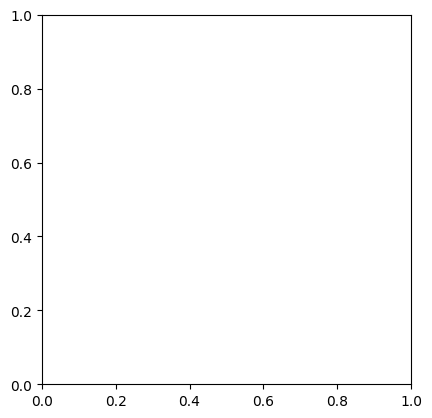

In [5]:
#get skeleton vessel in MRI projection
error = main_get_vessels_in_MRI(Mypath, params)
print(error)

#get skeleton vessel in Optical image
error = main_get_vessels_in_optics(Mypath, params)
print(error)

#plot
error,display = main_plot_vessel_skeletons(Mypath)

plt.figure()
plt.imshow(display)
plt.show()
print(error)


# [Debug] place optics on MRI

In [2]:
output_dir = Mypath.output_dir
main_path_optics = Mypath.main_path_optics

#Set filenames
filename_MRI = output_dir+"T1_proj_skeleton.nii.gz"
filename_mask_MRI = output_dir+"Mask_Proj_MRI.nii.gz"
filename_tumor = output_dir+"Mask_Proj_Tumor.nii.gz"


#Check if image is RGB or HSI
filename_initial_img = main_path_optics+"initial_img.png"
_,suffix_out_optics = is_RGB_optical_image(filename_initial_img)
filename_optics = output_dir+"optics_skeleton"+suffix_out_optics+".nii.gz"
filename_mask_otpics = output_dir+"optics_mask"+suffix_out_optics+".nii.gz"

#Load optics image resolution
res_opt_in_mm = float(np.loadtxt(main_path_optics+"resolution.txt"))


#Load files
MRI_proj = itk.imread(filename_MRI,itk.UC)
mask_MRI = itk.imread(filename_mask_MRI,itk.UC)
mask_tumor = itk.imread(filename_tumor,itk.UC)

Optics_img = itk.imread(filename_optics,itk.UC)
Optical_mask=  itk.imread(filename_mask_otpics,itk.UC)


#Get center of mass of tumor and optical mask
kp_Optics, kp_Optics_phys, _kpts_MRI_tumor, _kpts_MRI_tumor_phys = get_alignment_points(Optical_mask, Optics_img, MRI_proj, mask_tumor,
                                                                                        params.kpts_MRI_tumor, params.kpt_optics, params.touch_vessel)

kpts_MRI_tumor = _kpts_MRI_tumor
kpts_MRI_tumor_phys = _kpts_MRI_tumor_phys


id_kp_MRI = 0
kp_MRI_phys = kpts_MRI_tumor_phys[id_kp_MRI]
kp_MRI = kpts_MRI_tumor[id_kp_MRI]


#Change origin of optics slice to match keypoint
change_origin(filenames_MRI= [filename_MRI],
            filenames_optics= [filename_optics],
            kpt_Optics= kp_Optics_phys,
            kpt_MRI= kp_MRI_phys)


#Load volumes with origin changed
filename_MRI = filename_MRI.split('.')[0]+"_origin_changed.nii.gz"
filename_optics = filename_optics.split('.')[0]+"_origin_changed.nii.gz"
    

#Show registration for the minimal metric
open_itksnap_with_overlay(filename_MRI, filename_optics)

/home/caredda/Soft/itksnap-nightly-master-Linux-gcc64/itksnap-4.2.0-rc.1-20240311-Linux-gcc64/lib/snap-4.2.0-rc.1/ITK-SNAP: /lib64/libcurl.so.4: no version information available (required by /home/caredda/Soft/itksnap-nightly-master-Linux-gcc64/itksnap-4.2.0-rc.1-20240311-Linux-gcc64/lib/snap-4.2.0-rc.1/ITK-SNAP)


Launching ITK-SNAP


Return code : 0


# Optics to MRI Registration. 

The center of rotation is located on MRI projection at the center of mass of the tumor projection.
In the optical image, the center of rotation is located at the center of mass of the optical mask

Success


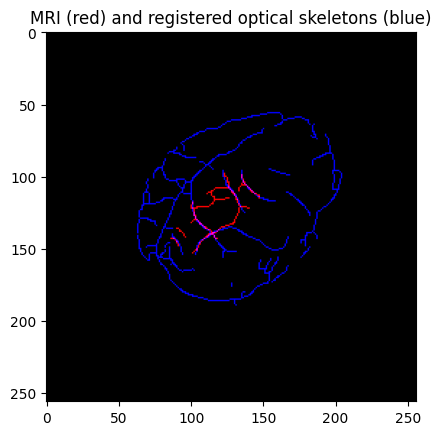

In [ ]:
#Process registration
# error = main_Optics_to_MRI_registration(Mypath, params)
# print(error)


#Plot registration results
error, display_img =  plot_registration_results(Mypath, params)
print(error)

plt.figure()
plt.title("MRI (red) and registered optical skeletons (blue)")
plt.imshow(cv.cvtColor(display_img,cv.COLOR_BGR2RGB))
plt.show()



# Project Optics image/stats on T1 [Create projection]
Problem: décallage en rotation quand use_upscaled_images = False 

Success
Success


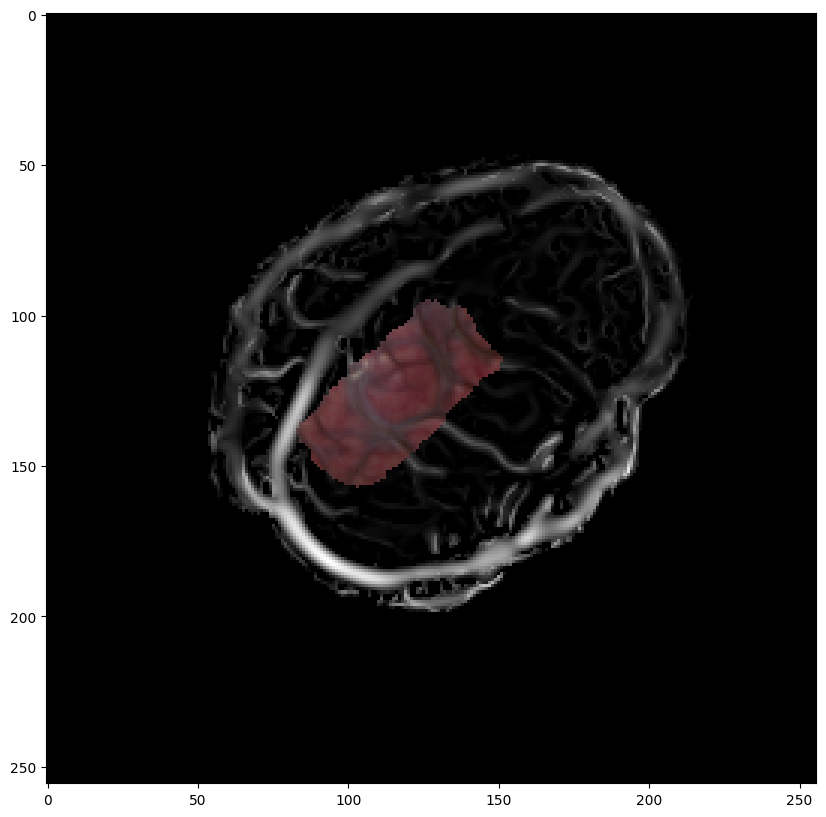

Success


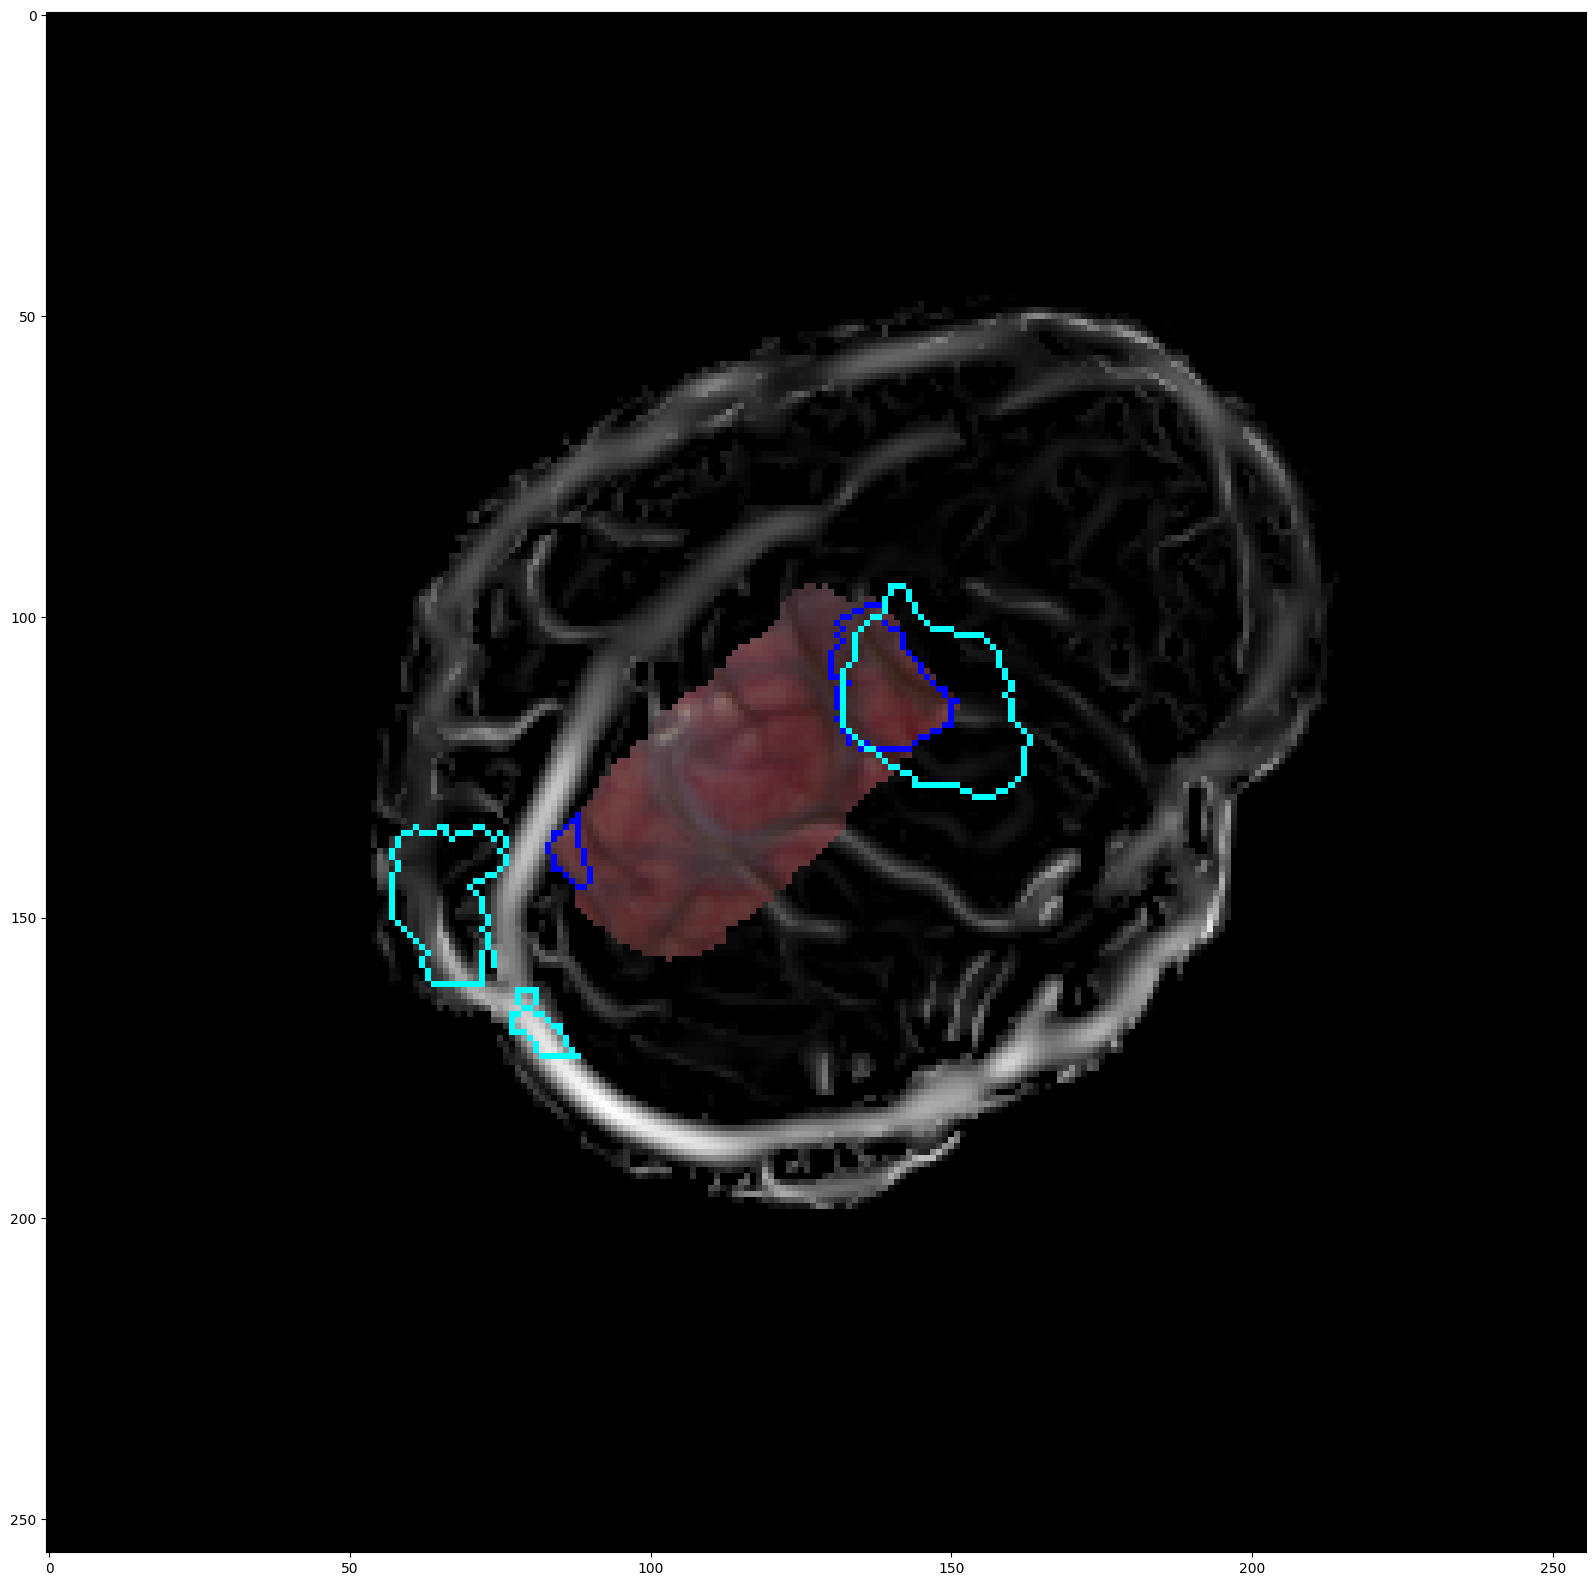

In [ ]:
#Project optical image/stats on MRI projection
error = main_project_optical_image_on_MRI(Mypath, params)
print(error)

#plot results
error,display2 = main_plot_Optical_image_projected_on_MRI(Mypath)
print(error)



plt.figure(figsize=(10,10))
plt.imshow(cv.cvtColor(display2,cv.COLOR_BGR2RGB))
plt.show()



#Project optical image/stats on MRI projection
#Check if optical imaging is RGB or HSI
_,suffix_out_optics = is_RGB_optical_image(Mypath.main_path_optics+"initial_img.png")


# # fMRI_filenames=[dir_fMRI+"r_RS_SCA_inferenceL_motor_rotated_Mask_proj.png",
# #                 dir_fMRI+"r_RS_SCA_inferenceR_motor_rotated_Mask_proj.png"]
# # fOptics_filenames = [dir_foptics+"RGB_inferenceL_reg_motor_mask.png",
# #                      dir_foptics+"RGB_inferenceR_reg_motor_mask.png"]

# # fMRI_filenames=[dir_fMRI+"r_RS_SCA_inferenceL_sensory_rotated_Mask_proj.png",
# #                 dir_fMRI+"r_RS_SCA_inferenceR_sensory_rotated_Mask_proj.png"]
# # fOptics_filenames = [dir_foptics+"RGB_inferenceL_reg_sensory_mask.png",
# #                      dir_foptics+"RGB_inferenceR_reg_sensory_mask.png"]


_fMRI_filenames = [Mypath.main_path+"/MRI/fMRI/inferences/"+"zone_MGfwe.nii"]        #r_zone_MGfwe_Mask_proj.png
_fOptics_filenames = [Mypath.main_path+"/optics/foptics_"+suffix_out_optics+"/"+"Z_stats_Hb.txt"]  #dir_foptics+"Z_stats_Hb_mask.png"
 




colors_fOptics = [(255,0,0),(0,0,255)]
colors_fMRI = [(255,255,0),(0,215,255)]

error, display = main_plot_fOptics_fMRI_stats_projected_on_MRI(Mypath,
                                                 _fMRI_filenames=_fMRI_filenames,
                                                 _fOptics_filenames=_fOptics_filenames,
                                                 colors_fMRI=colors_fMRI,
                                                 colors_fOptics=colors_fOptics)


print(error)
plt.figure(figsize=(20,20))
plt.imshow(cv.cvtColor(display,cv.COLOR_BGR2RGB))
plt.show()



# Create Optics volume registered in T1 space

In [2]:
#Create optical volume in T1 space
error = main_reconstruct_Optics_volume(Mypath)
print(error)

#Check if optical imaging is RGB or HSI
_,suffix_out_optics = is_RGB_optical_image(Mypath.main_path_optics+"initial_img.png")
open_MRIcroGL_with_overlay(Mypath.output_dir+"r_T1_bet.nii.gz", Mypath.output_dir + "Projection/Rec_Optical_T1"+suffix_out_optics+".nii.gz")


Success


Gtk-Message: 16:06:10.612: Failed to load module "pk-gtk-module"

(MRIcroGL:2510139): Gtk-WARNING **: 16:06:10.662: gtk_widget_size_request() called on child widget with request equal
 to widget->requisition. gtk_widget_set_usize() may not work properly.

(MRIcroGL:2510139): Gtk-WARNING **: 16:06:10.662: gtk_widget_size_request() called on child widget with request equal
 to widget->requisition. gtk_widget_set_usize() may not work properly.

(MRIcroGL:2510139): Gtk-WARNING **: 16:06:10.662: gtk_widget_size_request() called on child widget with request equal
 to widget->requisition. gtk_widget_set_usize() may not work properly.

(MRIcroGL:2510139): Gtk-WARNING **: 16:06:10.662: gtk_widget_size_request() called on child widget with request equal
 to widget->requisition. gtk_widget_set_usize() may not work properly.

(MRIcroGL:2510139): Gtk-WARNING **: 16:06:10.663: gtk_widget_size_request() called on child widget with request equal
 to widget->requisition. gtk_widget_set_usize() may not 

If there is a long delay at launch, ensure full GTK2 install: "sudo apt-get install appmenu-gtk2-module"
Unable to find AFNI_ATLAS_PATH 
Loading preferences /home/caredda/.MRIcroGL12.ini
uint8 range 0...255
uint8 window 0...250
Init time 0
Set Min/Max Window 0..250 time 0
Update RGBA time 0
Reading script /home/caredda/DVP/segmentation_registration_pipeline/Registration/module/display_MRIcroGL.py
ResourceDir: /home/caredda/Soft/MRIcroGL_linux1804/MRIcroGL/Resources PyLib: /home/caredda/Soft/MRIcroGL_linux1804/MRIcroGL/Resources
Loading modules....
Done Loading modules....
Load time 584
float range 0..101490.8671875
float window 0...0
Init time 494
Set Min/Max Window 0..101490.8671875 time 86
Update RGBA time 183
Load time 407
Reorient time 2451
float range 0..179.70425415039063
float window 0...0
Init time 499
blur proxy test 563x563x422
GPU Gradient time 361
gradientTexture3D proxy test 563x563x422
blur proxy test 563x563x422
GPU Gradient time 383
blur proxy test 563x563x422
GPU Gradi

# [Debug] Test refine projection (by taking into account the brain curvature)

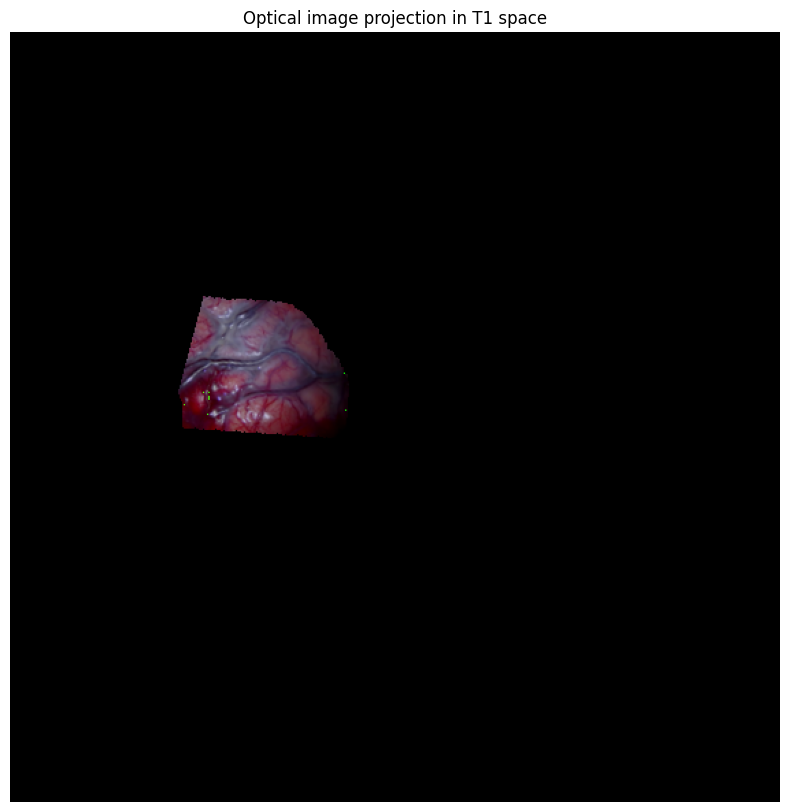

In [ ]:
main_path_optics = Mypath.main_path_optics
output_dir = Mypath.output_dir

#Check if optical imaging is RGB or HSI
filename_optics = main_path_optics+"initial_img.png"
if not os.path.exists(filename_optics):
    print("Optical image not found at")

_,suffix_out_optics = is_RGB_optical_image(filename_optics)

#Load optical volumes
B_vol = itk.imread(output_dir + "Projection/Rec_Optical_rotated_B"+suffix_out_optics+".nii.gz", itk.F)
G_vol = itk.imread(output_dir + "Projection/Rec_Optical_rotated_G"+suffix_out_optics+".nii.gz", itk.F)
R_vol = itk.imread(output_dir + "Projection/Rec_Optical_rotated_R"+suffix_out_optics+".nii.gz", itk.F)


filename_MRI_surface = output_dir+'surface_mask_rotated.nii.gz'
filename_tumor = output_dir+'Tumor_rotated.nii.gz'

surface = itk.imread(filename_MRI_surface, itk.F)
tumor = itk.imread(filename_tumor, itk.F)

# Get numpy arrays
np_B_vol = itk.GetArrayFromImage(B_vol)
np_G_vol = itk.GetArrayFromImage(G_vol)
np_R_vol = itk.GetArrayFromImage(R_vol)

np_surface = itk.GetArrayFromImage(surface)
np_tumor = itk.GetArrayFromImage(tumor)


# Calculate projection
np_B_vol_projection, np_mask, np_tumor_mask = create_MRI_projection_np(np_B_vol,
                                                                    np_surface,
                                                                    np_tumor,
                                                                    Projection=params.projection_type)

np_G_vol_projection, np_mask, np_tumor_mask = create_MRI_projection_np(np_G_vol,
                                                                    np_surface,
                                                                    np_tumor,
                                                                    Projection=params.projection_type)

np_R_vol_projection, np_mask, np_tumor_mask = create_MRI_projection_np(np_R_vol,
                                                                    np_surface,
                                                                    np_tumor,
                                                                    Projection=params.projection_type)


BGR_proj = np.zeros((np_B_vol_projection.shape[0], np_B_vol_projection.shape[1], 3), dtype=np.uint8)
BGR_proj[:, :, 0] = np_B_vol_projection.astype(np.uint8)
BGR_proj[:, :, 1] = np_G_vol_projection.astype(np.uint8)
BGR_proj[:, :, 2] = np_R_vol_projection.astype(np.uint8)

plt.figure(figsize=(10,10))
plt.imshow(cv.cvtColor(BGR_proj,cv.COLOR_BGR2RGB))
plt.axis('off')
plt.title("Optical image projection in T1 space")
plt.show()









float64


# [TEMP FOR ADITHEP] Create MRI seed image
1) Create mask
2) Run project optics image/stats on T1
3) Run Create Optics volume

In [ ]:

#seed image
filename_optics = Mypath.main_path_optics+"initial_img.png"
in_img = cv.imread(filename_optics)

#Seed image
pos = (200,379)
seed = np.zeros((in_img.shape[0],in_img.shape[1]),dtype=np.uint8)
seed[pos[0]-10:10+pos[0],pos[1]-10:10+pos[1]] = 255

np.savetxt(Mypath.main_path_optics+"foptics/RGB_seed_sensory.txt",seed)


# Project MRI on optical image

['/home/caredda/Videos/Optical_MRI_data/P_025/optics/foptics/Z_stats_Hb.txt']


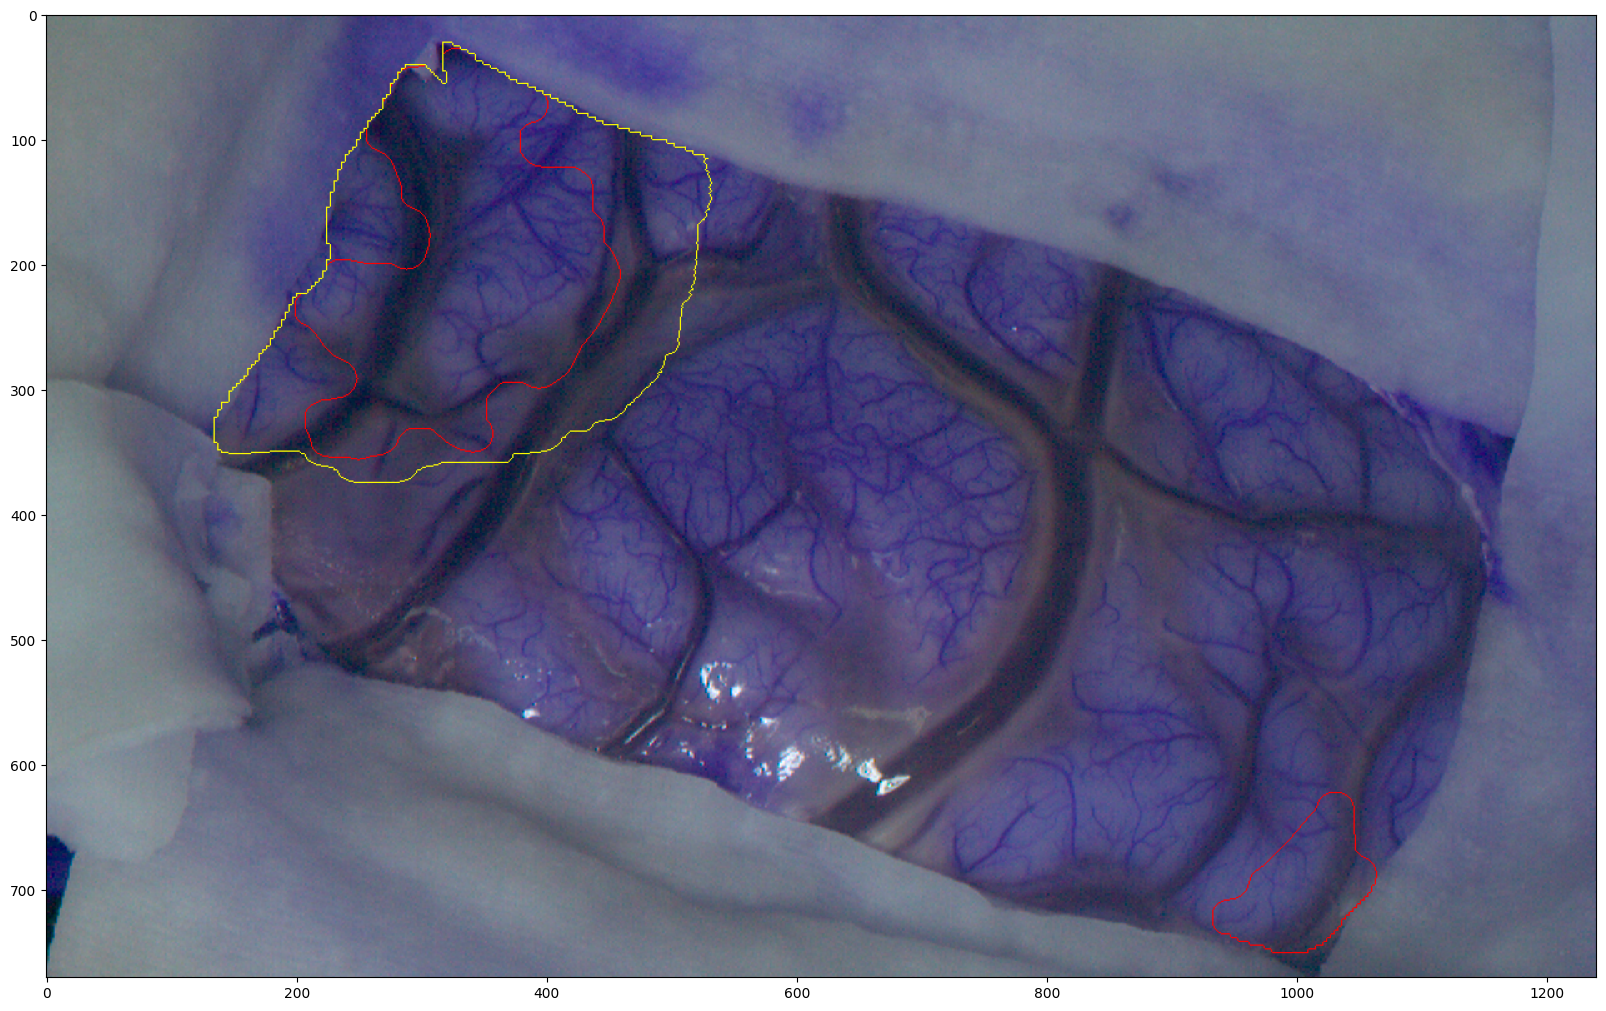

In [2]:
# #Project MRI on optics space
# error = main_project_MRI_in_optics_space(Mypath, params)
# print(error)

# #Plot results
# error,display = main_plot_MRI_projected_on_Optics_space(Mypath)
# print(error)

# plt.figure(figsize=(20,20))
# plt.imshow(display)
# plt.show()




#Project optical image/stats on MRI projection
#Check if optical imaging is RGB or HSI
_,suffix_out_optics = is_RGB_optical_image(Mypath.main_path_optics+"initial_img.png")
dir_fMRI = Mypath.output_dir + "Projection/fMRI/"
dir_foptics = Mypath.output_dir + "Projection/foptics_"+suffix_out_optics+"/"


fMRI_filenames = [Mypath.main_path+"/MRI/fMRI/inferences/"+"zone_MGfwe.nii"]        #r_zone_MGfwe_Mask_proj.png
fOptics_filenames = [Mypath.main_path_optics+"foptics/"+"Z_stats_Hb.txt"]  #dir_foptics+"Z_stats_Hb_mask.png"
print(fOptics_filenames)

colors_fOptics = [(255,0,0),(0,0,255)]
colors_fMRI = [(255,255,0),(0,215,255)]

error, display = main_plot_fOptics_fMRI_stats_projected_on_optics(Mypath,
                                                 _fMRI_filenames=fMRI_filenames,
                                                 _fOptics_filenames=fOptics_filenames,
                                                 colors_fMRI=colors_fMRI,
                                                 colors_fOptics=colors_fOptics)


plt.figure(figsize=(20,20))
plt.imshow(cv.cvtColor(display,cv.COLOR_BGR2RGB))
plt.show()

# Registration validation

In [ ]:
output_dir = Mypath.output_dir

print("Patient ID",Patient_ID_array[id_patient])

#Load images
mri = cv.imread(output_dir+"MRI_proj_enhanced.png",cv.IMREAD_ANYCOLOR)
optics = cv.imread(output_dir+"RGB_registered_on_MRI.png")

#Load landmarks
points_optics = np.loadtxt(output_dir+"verification_landmarks/optics.txt")#.astype(int)
points_mri = np.loadtxt(output_dir+"verification_landmarks/mri.txt")#.astype(int)

#Get MRI resolution
filename_MRI_proj = output_dir+"Proj_MRI.nii.gz"
MRI_proj = itk.imread(filename_MRI_proj, itk.F)
reso = np.array(MRI_proj.GetSpacing())


print("MRI resolution: ",reso )


#Compute Euclidean distance in pixels
dist_mm = np.sqrt(((points_optics[:,0] - points_mri[:,0])*reso[0])**2 + ((points_optics[:,1] - points_mri[:,1])*reso[1])**2)
print("Euclidean distance",dist_mm.mean(),dist_mm.std())



plt.figure(figsize=(20,20))
plt.subplot(121)
plt.imshow(optics)
for i in range(points_optics.shape[0]):
    plt.plot(points_optics[i,0],points_optics[i,1],'ro')
plt.subplot(122)
plt.imshow(mri)
for i in range(points_mri.shape[0]):
    plt.plot(points_mri[i,0],points_mri[i,1],'ro')
plt.show()


plt.figure(figsize=(20,20))
plt.imshow(mri)
for i in range(points_mri.shape[0]):
    plt.plot(points_mri[i,0],points_mri[i,1],'bo')

for i in range(points_optics.shape[0]):
    plt.plot(points_optics[i,0],points_optics[i,1],'ro')
plt.show()

# Create mesh of T1 and registered optical file

In [ ]:

output_dir = Mypath.output_dir
main_path_optics = Mypath.main_path_optics


# Load the MRI data
nsub = 3
mesh_mri = process_mesh(output_dir+'r_T1_bet.nii.gz',nsub)
mesh_optical = process_mesh(output_dir +"Rec_Optical_T1.nii.gz",nsub)

save_path = "/home/caredda/temp/"

# Save the mesh to an STL file
mesh_mri.save(save_path+"MRI_mesh.stl")
mesh_optical.save(save_path+"Optics_mesh.stl")

#save texture for optics
input_img = cv.imread(main_path_optics+"initial_img.png")
mask = (cv.imread(main_path_optics+"mask.png",cv.IMREAD_GRAYSCALE)/255).astype(np.uint8)
for i in range(input_img.shape[2]):
    input_img[:,:,i] *= mask
cv.imwrite(save_path+"texture_optics.png",input_img)


